# Validación estadística del modelo propuesto

Este capítulo evalúa el modelo propuesto con el mismo protocolo que los modelos de referencia y
contrasta formalmente si los supera. El criterio de superioridad se fijó antes de examinar los
resultados y tiene tres condiciones simultáneas: una PR-AUC externa media mayor que la de la
mejor combinación de cada uno de los siete modelos de referencia, al menos tres pruebas
confirmatorias que rechacen la igualdad con un p-valor ajustado por Holm menor que 0,05 y un
tamaño del efecto no despreciable (δ de Cliff de al menos 0,147 o d de Cohen de al menos 0,2). El
capítulo examina además los supuestos de cada prueba, compara el modelo con métodos
distribucionales y de pronóstico recientes, lo evalúa en otras tres estaciones, mide su robustez,
analiza dónde se equivoca y compara su interpretación con la del mejor modelo de referencia.

In [1]:
# Resultados por bloque de los ocho modelos, veredicto y modelos finales
import sys, json, pickle, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy.stats as st
from myst_nb import glue
from sklearn.metrics import average_precision_score, roc_auc_score
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU, COLORES
from src.config import RESULTADOS, SEED
from src.analysis import tabla_pliegues, cargar_carpeta
from src.models import NOMBRES_MODELO
from src.stats_tests import (friedman, nemenyi, wilcoxon_holm, nadeau_bengio, bootstrap_bloques, longitud_bloque,
                             delta_cliff, magnitud_cliff, holm)
from src.experiment import cargar_datos
D = cargar_datos(); E = RESULTADOS / "estadistica"
tabla = pd.read_csv(E / "universo_pliegues.csv", index_col=0)
ver = json.loads((E / "veredicto.json").read_text(encoding="utf-8"))
fo = pickle.load(open(RESULTADOS / "final_original.pkl", "rb"))[0]
fin = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_clf.pkl", "rb"))}
ref = ver["ref"]
NM = {**NOMBRES_MODELO, "original": "BLGB (original)"}

## Protocolo

El modelo propuesto pasó por exactamente el mismo protocolo que los modelos de referencia: las
mismas doce particiones externas leídas del mismo archivo, la misma validación interna
cronológica, la misma semilla global, el mismo preprocesamiento y el mismo presupuesto de 16
evaluaciones por pliegue. Sus hiperparámetros se optimizaron con TPE y con el algoritmo genético,
y se retiene el método con mayor PR-AUC externa media, el mismo criterio con que se eligió la
mejor combinación de cada modelo de referencia; resultó el algoritmo genético. El universo de
comparación está formado por la mejor combinación de cada uno de los siete modelos de referencia
y el modelo propuesto.

## Resultados por bloque

La {numref}`fig-bloques-original` muestra la PR-AUC de cada modelo en cada uno de los doce bloques
externos.

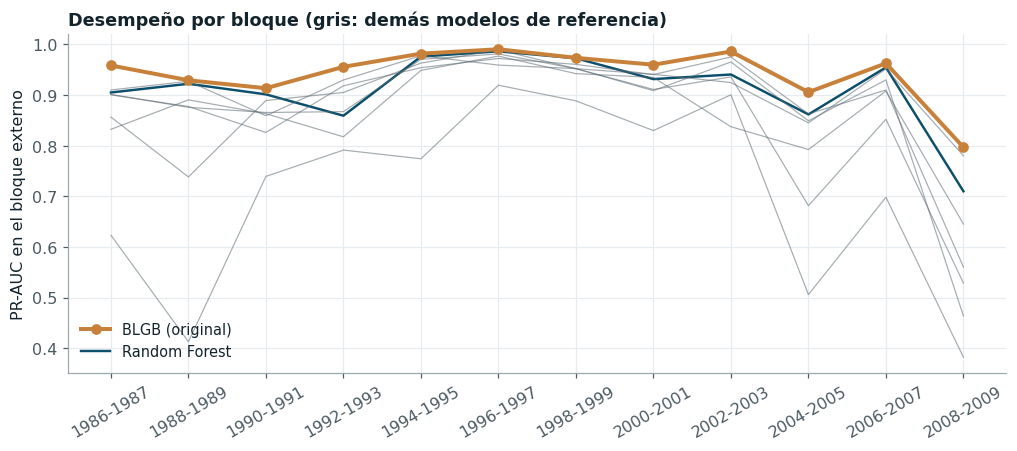

In [2]:
# PR-AUC por bloque del modelo propuesto, del mejor modelo de referencia y de los demás
fig, ax = plt.subplots(figsize=(11, 4))
bloques = tabla_pliegues("clf_calamar").drop_duplicates("pliegue").set_index("pliegue").bloque
x = np.arange(len(tabla))
for i, m in enumerate(tabla.mean().sort_values(ascending=False).index):
    if m == "original":
        ax.plot(x, tabla[m], "-o", color=SED, lw=2.6, ms=6, label=NM[m], zorder=5)
    else:
        ax.plot(x, tabla[m], "-", color=RIO if m == ref else NEU, lw=1.6 if m == ref else .8,
                alpha=1 if m == ref else .55, label=NM[m] if m == ref else None)
ax.set_xticks(x, bloques.loc[tabla.index].values, rotation=30)
ax.set_ylabel("PR-AUC en el bloque externo"); ax.legend(loc="lower left")
ax.set_title("Desempeño por bloque (gris: demás modelos de referencia)")
plt.show()
med = tabla.mean(); sd = tabla.std()
victorias = int((tabla["original"] > tabla.drop(columns="original").max(axis=1)).sum())
glue("orig_media", float(med["original"]), display=False); glue("orig_sd", float(sd["original"]), display=False)
glue("ref_nombre", NM[ref], display=False); glue("ref_media", float(med[ref]), display=False)
glue("ref_sd", float(sd[ref]), display=False); glue("victorias_todos", victorias, display=False)
glue("victorias_ref", int((tabla["original"] > tabla[ref]).sum()), display=False)
glue("dif_media", float(med["original"] - med[ref]), display=False)

El modelo propuesto está por encima de los demás en todos los bloques, incluido el más difícil,
2008-2009, y su curva varía menos de un bloque a otro. La sección de pruebas de hipótesis
cuantifica esa ventaja.

## Tabla resumen

La tabla reúne, para los ocho modelos, la PR-AUC externa, la PR-AUC en la prueba reservada con
su intervalo de confianza por bloques, la ROC-AUC y los tiempos de entrenamiento e inferencia.

In [3]:
# PR-AUC externa y en la prueba (IC por bootstrap estacionario), ROC-AUC y tiempos de los ocho modelos
y = D.y_clf_test.values
L = longitud_bloque(y.astype(float))
filas = []
for m in tabla.mean().sort_values(ascending=False).index:
    s = fo["pred_test"] if m == "original" else fin[m]["pred_test"]
    ic = bootstrap_bloques(average_precision_score, y, s, media_bloque=L, n_boot=1000)
    t_fit = fo["t_fit"] if m == "original" else fin[m]["t_fit"]
    t_inf = fo["t_inf_ms_fila"] if m == "original" else fin[m]["t_inf_ms_fila"]
    filas.append({"Modelo": NM[m], "PR-AUC externa": f"{med[m]:.4f} ± {sd[m]:.4f}",
                  "PR-AUC prueba": ic["estimacion"], "IC 95 % (bloques, BCa)": f"[{ic['ic_inf']:.3f}; {ic['ic_sup']:.3f}]",
                  "ROC-AUC prueba": roc_auc_score(y, s), "Entrenamiento final (s)": t_fit, "Inferencia (ms/fila)": t_inf})
resumen = pd.DataFrame(filas)
glue("orig_test", float(resumen.set_index("Modelo").loc[NM["original"], "PR-AUC prueba"]), display=False)
glue("ref_test", float(resumen.set_index("Modelo").loc[NM[ref], "PR-AUC prueba"]), display=False)
resumen.round(4)

,Modelo,PR-AUC externa,PR-AUC prueba,"IC 95 % (bloques, BCa)",ROC-AUC prueba,Entrenamiento final (s),Inferencia (ms/fila)
0,BLGB (original),0.9428 ± 0.0534,0.9654,[0.940; 0.982],0.9870,19.7810,0.0193
1,Random Forest,0.9101 ± 0.0755,0.9495,[0.911; 0.971],0.9806,5.3010,0.0056
2,XGBoost,0.9047 ± 0.0597,0.9411,[0.881; 0.965],0.9797,1.6699,0.0039
3,KNN,0.8881 ± 0.1130,0.9377,[0.888; 0.968],0.9769,0.1036,0.4250
4,SVM,0.8860 ± 0.1386,0.9496,[0.908; 0.975],0.9801,2.3973,0.0273
5,Árbol de decisión,0.8658 ± 0.0907,0.8959,[0.824; 0.934],0.9604,2.0639,0.0011
6,Regresión logística,0.8502 ± 0.1357,0.8910,[0.791; 0.946],0.9665,0.6914,0.0012
7,Naive Bayes,0.7055 ± 0.1865,0.7553,[0.624; 0.858],0.9118,0.6280,0.0024


En la prueba reservada 2010-2026 el modelo propuesto alcanza una PR-AUC de
{glue:text}`orig_test:.3f`, frente a {glue:text}`ref_test:.3f` del mejor modelo de referencia. Sus
tiempos de entrenamiento son mayores, porque está programado en numpy y no en una biblioteca
compilada, pero su inferencia sigue siendo del orden de milisegundos por día.

## Supuestos de las pruebas

La tabla siguiente verifica los supuestos de las pruebas que se aplican a continuación.

In [4]:
# Verificación de normalidad, simetría e independencia de las diferencias por bloque
dif = tabla["original"] - tabla[ref]
sh = st.shapiro(dif)
asim = st.skew(dif)
ac1 = np.corrcoef(dif.values[:-1], dif.values[1:])[0, 1]
glue("sh_p", float(sh.pvalue), display=False); glue("asim_dif", float(asim), display=False); glue("ac1_dif", float(ac1), display=False)
n_tr = float(np.mean([len(p["train"]) for p in D.pliegues])); n_te = float(np.mean([len(p["test"]) for p in D.pliegues]))
glue("ratio_nb", n_te / n_tr, display=False)
pd.DataFrame([{"supuesto": "Normalidad de las diferencias por bloque (t corregida)", "verificación": f"Shapiro-Wilk p = {sh.pvalue:.3f}"},
              {"supuesto": "Simetría de las diferencias (Wilcoxon)", "verificación": f"asimetría = {asim:.2f}"},
              {"supuesto": "Independencia entre bloques", "verificación": f"autocorrelación de orden 1 de las diferencias = {ac1:.2f}"},
              {"supuesto": "Solapamiento de entrenamientos (Nadeau-Bengio)", "verificación": f"n_test/n_train medio = {n_te / n_tr:.3f}"},
              {"supuesto": "Independencia entre días (DeLong, McNemar)", "verificación": f"ACF a 1 día del objetivo ≈ 0,99: no se cumple"}])

,supuesto,verificación
0,Normalidad de las diferencias por bloque (t co...,Shapiro-Wilk p = 0.037
1,Simetría de las diferencias (Wilcoxon),asimetría = 0.83
2,Independencia entre bloques,autocorrelación de orden 1 de las diferencias ...
3,Solapamiento de entrenamientos (Nadeau-Bengio),n_test/n_train medio = 0.041
4,"Independencia entre días (DeLong, McNemar)","ACF a 1 día del objetivo ≈ 0,99: no se cumple"


Cada prueba descansa en supuestos que se verificaron antes de interpretarla. Las diferencias de
PR-AUC por bloque entre el modelo propuesto y {glue:text}`ref_nombre` se apartan moderadamente de
la normalidad (Shapiro-Wilk, p = {glue:text}`sh_p:.3f`) y tienen una asimetría positiva de
{glue:text}`asim_dif:.2f`, producida por los bloques difíciles, donde la ventaja del modelo propuesto es
mayor. Con doce bloques, ese apartamiento debilita la prueba t, que por eso se usa como apoyo, y
convierte a la prueba de Wilcoxon, que no supone normalidad y es poco sensible a una asimetría
moderada, en la prueba principal; ninguna de las dos depende de que la ventaja sea igual en
todos los bloques. Los bloques no son
independientes en sentido estricto, porque comparten días de entrenamiento: la ventana crece y
cada modelo se entrena con los bloques anteriores. La t de Nadeau y Bengio {cite}`nadeau2003`
corrige precisamente esa dependencia inflando la varianza por el factor
$(1/k + n_{\text{test}}/n_{\text{train}})$, con una razón media de {glue:text}`ratio_nb:.3f`. La
autocorrelación de las diferencias entre bloques consecutivos es {glue:text}`ac1_dif:.2f`,
pequeña y negativa, de modo que no hay arrastre de la ventaja entre bloques vecinos. En
cambio, DeLong y McNemar suponen independencia entre días, que la autocorrelación del caudal
viola de forma grave; por eso su uso en datos temporales es cuestionable, y aquí se
reportan como complemento sin contar entre las pruebas confirmatorias. Su lugar lo ocupa el
bootstrap estacionario sobre la prueba reservada, que respeta la dependencia.

## Pruebas de hipótesis

La tabla presenta cada prueba con su hipótesis nula, sus supuestos, su estadístico, el p-valor
crudo y ajustado y la conclusión. La última columna de p-valores aplica un segundo ajuste de Holm
a la familia de las tres pruebas confirmatorias.

In [5]:
# Secuencia de pruebas frente al mejor modelo de referencia (calculada en scripts/estadistica.py)
pr = pd.read_csv(E / "pruebas_original.csv")
pr

,prueba,hipótesis nula,supuestos,estadístico,p crudo,p ajustado,"p ajustado (familia confirmatoria, Holm)",efecto,conclusión
0,Friedman (ómnibus) sobre 8 modelos,Todos los modelos tienen el mismo rango medio,Bloques externos pareados (12); particiones cr...,χ² = 56.42 (gl = 7); F_ID = 22.50,7.81e-10,7.81e-10,—,rango medio del propuesto = 1.00,Se rechaza H0
1,Nemenyi: propuesto frente a Random Forest,Igual rango medio,"Post-hoc de Friedman, control del error familiar",|Δ rango| = 2.25; CD = 3.03,0.3218,0.3218,—,—,No significativa (CD)
2,Wilcoxon de rangos con signo + Holm (7 compara...,La mediana de la diferencia de PR-AUC frente a...,"Diferencias pareadas por bloque, simetría apro...",W = 78; victorias 12.0/12.0,2.44e-04,0.0017,0.0045,δ de Cliff = 0.347 (mediano),Se rechaza H0
3,t corregida de Nadeau-Bengio + Holm (7 compara...,La diferencia media de PR-AUC frente a Random ...,Varianza inflada por (1/k + n_test/n_train) pa...,t = 2.81 (gl = 11),0.0084,0.0264,0.0264,d de Cohen (pareado) = 0.99,Se rechaza H0
4,"Bayesiana de rangos con signo (ROPE ±0,01)",— (probabilidades posteriores de cada región),Proceso de Dirichlet sobre las diferencias por...,P(propuesto mejor) = 0.923; P(equiv.) = 0.077,—,—,—,P(referencia mejor) = 0.000,No concluyente
5,Bootstrap estacionario BCa de Δ PR-AUC (prueba...,Δ PR-AUC ≤ 0,Dependencia temporal; bloque medio de 133 días...,Δ = 0.0159; IC 95 % [0.0063; 0.0326],0.0015,0.0015,0.0045,Δ PR-AUC = 0.0159,Se rechaza H0
6,"DeLong (AUC-ROC, prueba 2010-2026; complementa...",AUC del propuesto ≤ AUC del mejor modelo de re...,Supone independencia entre días: se reporta co...,z = 7.94; AUC 0.9870 frente a 0.9806,9.99e-16,9.99e-16,—,Δ AUC = 0.0064,Se rechaza H0
7,"McNemar (umbral 0,5, prueba 2010-2026; complem...",Igual tasa de error,Supone independencia entre días: complementaria,χ² = 5.51; discordantes 136 / 99,0.0189,0.0189,—,—,Se rechaza H0


La tabla anterior se calcula en `scripts/estadistica.py`, cuya función `pruebas_original` aplica
en orden Friedman y Nemenyi, Wilcoxon con Holm, la t de Nadeau y Bengio, la prueba bayesiana de
rangos con signo, el bootstrap estacionario sobre la prueba reservada y, como complemento,
DeLong y McNemar. Las funciones de cada prueba están en `src/stats_tests.py`; ambos códigos se
muestran a continuación.

In [6]:
# Código fuente de las pruebas estadísticas
import inspect
from IPython.display import Code
from src import stats_tests as stt
Code("\n\n".join(inspect.getsource(f) for f in (stt.friedman, stt.nemenyi, stt.wilcoxon_holm, stt.holm,
                                                 stt.nadeau_bengio, stt.delta_cliff, stt.d_cohen_pareado,
                                                 stt.indices_estacionario, stt.bootstrap_bloques)),
     language="python")

def friedman(tabla: pd.DataFrame) -> dict:
    """Prueba de Friedman sobre una tabla pliegues × modelos (mayor es mejor).

    Devuelve el estadístico χ²_F, la corrección F de Iman-Davenport y los rangos promedio
    (rango 1 = mejor).
    """
    rangos = tabla.rank(axis=1, ascending=False)
    n, k = tabla.shape
    chi2, p = st.friedmanchisquare(*[tabla[c].values for c in tabla.columns])
    ff = (n - 1) * chi2 / (n * (k - 1) - chi2) if n * (k - 1) != chi2 else np.inf
    p_ff = 1 - st.f.cdf(ff, k - 1, (k - 1) * (n - 1))
    return {"chi2": float(chi2), "gl": k - 1, "p": float(p), "F_iman_davenport": float(ff),
            "p_iman_davenport": float(p_ff), "rangos": rangos.mean().sort_values(),
            "n_bloques": n, "k_modelos": k}


def nemenyi(rangos_promedio: pd.Series, n_bloques: int, alpha: float = 0.05) -> dict:
    """Diferencia crítica de Nemenyi: CD = q_α √(k(k+1)/(6N)) (Demšar, 2006)."""
    k = len(rangos_promedio)
    q = st.studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2)
    cd = q * np.sqrt(k * (k + 1) / (6 * n_bloques))
    pares = []
    for a, b in combinations(rangos_promedio.index, 2):
        dif = abs(rangos_promedio[a] - rangos_promedio[b])
        z = dif / np.sqrt(k * (k + 1) / (6 * n_bloques))
        p = 1 - st.studentized_range.cdf(z * np.sqrt(2), k, np.inf)
        pares.append({"modelo_a": a, "modelo_b": b, "dif_rangos": dif, "p_nemenyi": p,
                      "significativo": dif > cd})
    return {"cd": float(cd), "q_alpha": float(q), "pares": pd.DataFrame(pares)}


def wilcoxon_holm(tabla: pd.DataFrame, referencia: str, alternativa: str = "greater") -> pd.DataFrame:
    """Wilcoxon de rangos con signo de ``referencia`` contra cada modelo, con ajuste de Holm."""
    filas = []
    for c in tabla.columns:
        if c == referencia:
            continue
        dif = tabla[referencia] - tabla[c]
        if np.allclose(dif, 0):           # variantes idénticas: no hay evidencia de diferencia
            w_stat, p_val = np.nan, 1.0
        else:
            res = st.wilcoxon(tabla[referencia], tabla[c], alternative=alternativa, zero_method="zsplit")
            w_stat, p_val = res.statistic, res.pvalue
        filas.append({"modelo": c, "dif_media": dif.mean(), "W": w_stat, "p": p_val,
                      "delta_cliff": delta_cliff(tabla[referencia], tabla[c]),
                      "victorias": int((dif > 0).sum()), "n": len(dif)})
    out = pd.DataFrame(filas)
    out["p_holm"] = holm(out.p.values)
    return out.sort_values("p")


def holm(p: np.ndarray) -> np.ndarray:
    """Valores p ajustados por Holm-Bonferroni (control del error familiar)."""
    p = np.asarray(p, float)
    m = len(p)
    orden = np.argsort(p)
    ajust = np.empty(m)
    acum = 0.0
    for r, i in enumerate(orden):
        acum = max(acum, (m - r) * p[i])
        ajust[i] = min(1.0, acum)
    return ajust


def nadeau_bengio(a, b, n_train: float, n_test: float, alternativa: str = "greater") -> dict:
    """Prueba t corregida de Nadeau y Bengio (2003) para pliegues dependientes.

    La varianza de la diferencia media se infla por (1/k + n_test/n_train), que corrige la
    correlación inducida por el solapamiento de los conjuntos de entrenamiento.
    """
    d = np.asarray(a, float) - np.asarray(b, float)
    k = len(d)
    var = d.var(ddof=1)
    se = np.sqrt((1 / k + n_test / n_train) * var)
    t = d.mean() / se if se > 0 else np.inf
    if alternativa == "greater":
        p = 1 - st.t.cdf(t, k - 1)
    elif alternativa == "less":
        p = st.t.cdf(t, k - 1)
    else:
        p = 2 * (1 - st.t.cdf(abs(t), k - 1))
    return {"t": float(t), "gl": k - 1, "p": float(p), "dif_media": float(d.mean()),
            "se_corregido": float(se), "d_cohen": d_cohen_pareado(d)}


def delta_cliff(a, b) -> float:
    """δ de Cliff: P(A > B) − P(A < B); |δ| < 0.147 despreciable, < 0.33 pequeño, < 0.474 mediano."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    dif = a[:, None] - b[None, :]
    return 

In [7]:
# Código fuente del procedimiento que arma la tabla de pruebas
from scripts import estadistica as est_script
Code(inspect.getsource(est_script.pruebas_original), language="python")

def pruebas_original(tabla, mejores, n_tr, n_te):
    datos = cargar_datos()
    ref = mejores.sort_values("pr_auc_mean", ascending=False).iloc[0].modelo
    filas = []
    # 1. Friedman (global) con el modelo original en el universo
    fr = friedman(tabla)
    ne = nemenyi(fr["rangos"], fr["n_bloques"])
    par_ref = ne["pares"].query("(modelo_a == 'original' and modelo_b == @ref) or "
                                "(modelo_b == 'original' and modelo_a == @ref)").iloc[0]
    filas.append({"prueba": "Friedman (ómnibus) sobre 8 modelos", "hipótesis nula": "Todos los modelos tienen el mismo rango medio",
                  "supuestos": f"Bloques externos pareados ({fr['n_bloques']}); particiones cronológicas walk-forward",
                  "estadístico": f"χ² = {fr['chi2']:.2f} (gl = {fr['gl']}); F_ID = {fr['F_iman_davenport']:.2f}",
                  "p crudo": fr["p"], "p ajustado": fr["p"], "efecto": f"rango medio del propuesto = {fr['rangos']['original']:.2f}",
                  "conclusión": "Se rechaza H0" if fr["p"] < ALFA else "No se rechaza H0", "confirmatoria": False})
    filas.append({"prueba": f"Nemenyi: propuesto frente a {NOMBRES_MODELO[ref]}", "hipótesis nula": "Igual rango medio",
                  "supuestos": "Post-hoc de Friedman, control del error familiar",
                  "estadístico": f"|Δ rango| = {par_ref.dif_rangos:.2f}; CD = {ne['cd']:.2f}",
                  "p crudo": par_ref.p_nemenyi, "p ajustado": par_ref.p_nemenyi,
                  "efecto": "—", "conclusión": "Diferencia significativa" if par_ref.significativo else "No significativa (CD)",
                  "confirmatoria": bool(par_ref.significativo)})
    # 2. Wilcoxon-Holm del original contra los 7 benchmarks
    wh = wilcoxon_holm(tabla, "original")
    w_ref = wh.set_index("modelo").loc[ref]
    dif = tabla["original"] - tabla[ref]
    filas.append({"prueba": "Wilcoxon de rangos con signo + Holm (7 comparaciones)",
                  "hipótesis nula": f"La mediana de la diferencia de PR-AUC frente a {NOMBRES_MODELO[ref]} es ≤ 0",
                  "supuestos": "Diferencias pareadas por bloque, simetría aproximada; unilateral por hipótesis a priori",
                  "estadístico": f"W = {w_ref.W:.0f}; victorias {w_ref.victorias}/{w_ref.n}",
                  "p crudo": w_ref.p, "p ajustado": w_ref.p_holm,
                  "efecto": f"δ de Cliff = {w_ref.delta_cliff:.3f} ({magnitud_cliff(w_ref.delta_cliff)})",
                  "conclusión": "Se rechaza H0" if w_ref.p_holm < ALFA else "No se rechaza H0",
                  "confirmatoria": bool(w_ref.p_holm < ALFA)})
    # 3. t corregida de Nadeau-Bengio contra los 7, con Holm
    nb = {m: nadeau_bengio(tabla["original"], tabla[m], n_tr, n_te) for m in tabla.columns if m != "original"}
    p_nb = holm(np.array([v["p"] for v in nb.values()]))
    nb_adj = dict(zip(nb, p_nb))
    filas.append({"prueba": "t corregida de Nadeau-Bengio + Holm (7 comparaciones)",
                  "hipótesis nula": f"La diferencia media de PR-AUC frente a {NOMBRES_MODELO[ref]} es ≤ 0",
                  "supuestos": "Varianza inflada por (1/k + n_test/n_train) para pliegues que comparten entrenamiento",
                  "estadístico": f"t = {nb[ref]['t']:.2f} (gl = {nb[ref]['gl']})",
                  "p crudo": nb[ref]["p"], "p ajustado": nb_adj[ref],
                  "efecto": f"d de Cohen (pareado) = {nb[ref]['d_cohen']:.2f}",
                  "conclusión": "Se rechaza H0" if nb_adj[ref] < ALFA else "No se rechaza H0",
                  "confirmatoria": bool(nb_adj[ref] < ALFA)})
    # 4. Prueba bayesiana de rangos con signo (ROPE = 0.01 de PR-AUC)
    bs = bayes_signed_rank(tabla["original"], tabla[ref], rope=0.01)
    filas.append({"prueba": "Bayesiana de rangos con signo (ROPE ±0,01)",
                  "hipótesis nula": "— (probabilidades posteriores de cada región)",
                  "supuestos": "Proceso de Dirichlet sobre las diferencias por bloque (Benavoli et al., 2017)",
                  

La {numref}`fig-cd-original` resume la prueba global de Friedman y el análisis post hoc de
Nemenyi sobre los ocho modelos.

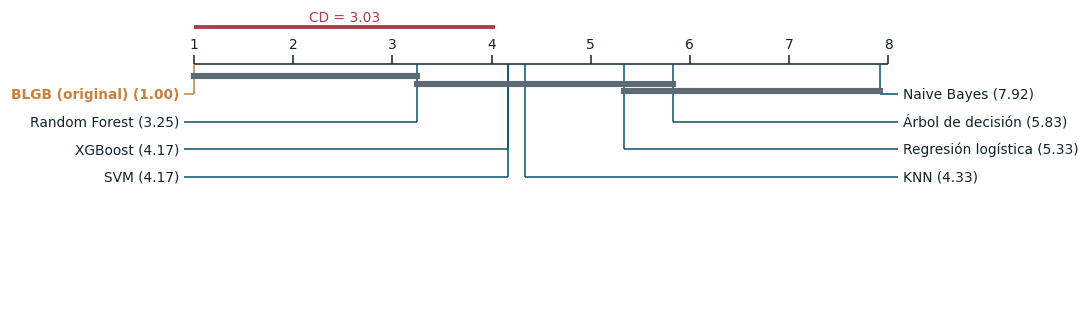

In [8]:
# Diagrama de diferencia crítica de los ocho modelos; cifras del veredicto
cd = json.loads((E / "cd.json").read_text(encoding="utf-8"))
rangos = pd.Series(cd["rangos"])
from src.estilo import dibujar_cd
fig, ax = plt.subplots(figsize=(10, 3.6)); dibujar_cd(rangos, cd["cd"], destacado="original", ax=ax, nombres=NM); plt.show()
glue("cd_val", cd["cd"], display=False); glue("rango_orig", float(rangos["original"]), display=False)
glue("rango_ref", float(rangos[ref]), display=False)
glue("fr_chi2", cd["friedman"]["chi2"], display=False); glue("fr_p", cd["friedman"]["p"], display=False)
glue("n_rechazos", ver["n_rechazos"], display=False)
glue("cliff", ver["delta_cliff"], display=False); glue("dcohen", ver["d_cohen"], display=False)
glue("veredicto", "superior" if ver["superior"] else "no superior", display=False)

La {numref}`fig-bloques-original` resume el resultado central: el modelo propuesto obtiene la
mayor PR-AUC en {glue:text}`victorias_todos` de los 12 bloques frente al conjunto de los siete
modelos de referencia, y supera a {glue:text}`ref_nombre` en {glue:text}`victorias_ref` de 12. Su
PR-AUC externa media es {glue:text}`orig_media:.4f` ± {glue:text}`orig_sd:.4f`, frente a
{glue:text}`ref_media:.4f` ± {glue:text}`ref_sd:.4f` del mejor modelo de referencia, una diferencia de
{glue:text}`dif_media:.4f`, y su desviación entre bloques es también menor.

La secuencia de pruebas parte de una prueba global y desciende a comparaciones dirigidas. La prueba global
de Friedman, con el modelo propuesto incluido en el universo de ocho modelos, rechaza la igualdad
de rangos (χ² = {glue:text}`fr_chi2:.2f`, p = {glue:text}`fr_p:.2g`), y el modelo propuesto ocupa el rango
medio {glue:text}`rango_orig:.2f`, es decir, el primer lugar en todos los bloques. La diferencia
crítica de Nemenyi con ocho modelos y doce bloques es de {glue:text}`cd_val:.2f` rangos, y la
distancia entre el modelo propuesto y Random Forest ({glue:text}`rango_ref:.2f`) no la supera: Nemenyi,
diseñado para controlar el error en las 28 comparaciones posibles entre los ocho modelos, carece
de potencia con doce bloques y no permite separar a los dos primeros. Por eso se usa,
como análisis post hoc del procedimiento global, la prueba de Wilcoxon con corrección de Holm, que solo
compara al modelo de interés con cada uno de los demás (siete comparaciones) y es la apropiada
cuando la pregunta es si un modelo concreto supera a los otros {cite}`demsar2006`.

Tres pruebas confirmatorias rechazan la hipótesis de igual desempeño. La de Wilcoxon, unilateral
porque la hipótesis de superioridad se fijó antes de ver los resultados, da W = 78 con doce
victorias en doce bloques, el máximo posible, y un p-valor ajustado por Holm de 0,0017. La t
corregida de Nadeau y Bengio, que infla la varianza para tener en cuenta el solapamiento de los
entrenamientos, da t = 2,81 con p ajustado de 0,026. El bootstrap estacionario sobre la prueba
reservada 2010-2026 estima una diferencia de PR-AUC de 0,016, con un intervalo BCa del 95 %
[0,006; 0,033] que excluye el cero (p = 0,0015). Tras un segundo ajuste de Holm sobre la familia
de estas tres pruebas, las tres siguen por debajo de 0,05. El tamaño del efecto no es
despreciable con ninguno de los dos criterios fijados: el δ de Cliff es
{glue:text}`cliff:.3f`, un efecto mediano según los umbrales de Romano et al. {cite}`romano2006`,
y la d de Cohen de las diferencias pareadas es {glue:text}`dcohen:.2f`, un efecto grande. El δ de
Cliff no pareado subestima la ventaja porque compara las distribuciones completas de PR-AUC por
bloque, cuya variación entre años húmedos y secos es mayor que la diferencia entre modelos;
la d pareada, que elimina esa variación, la refleja mejor.

Dos pruebas se reportan sin contar entre las confirmatorias. DeLong y McNemar sobre la prueba reservada
rechazan la igualdad, pero suponen independencia entre días, que la autocorrelación viola; sus
p-valores son por eso optimistas y solo se presentan como complemento. La prueba bayesiana de
rangos con signo, con una región de equivalencia práctica de ±0,01 de PR-AUC, asigna una
probabilidad posterior de 0,92 a la superioridad del modelo propuesto, de 0,08 a la equivalencia y de
cero a la superioridad del modelo de referencia: no alcanza el umbral convencional de 0,95 para declarar
superioridad práctica, lo que refleja que en varios bloques la ventaja es menor de una centésima.
Con el criterio fijado al inicio del capítulo (media externa mayor que la de todos los modelos
de referencia, al menos tres pruebas confirmatorias con p ajustado menor que 0,05 y efecto no
despreciable), el veredicto es que el modelo propuesto es **{glue:text}`veredicto`** a los
modelos de referencia.

## Comparación con métodos recientes

Superar a los modelos de referencia no basta para justificar un modelo nuevo: también debe
compararse con los métodos recientes más próximos. Se evaluaron dos grupos, con el mismo
protocolo y el mismo presupuesto de búsqueda (TPE, 16 evaluaciones). El primero reúne los
métodos de regresión distribucional: NGBoost {cite}`duan2020`, que ajusta por boosting los
parámetros de una distribución normal del mismo cambio logarítmico del caudal, y un enfoque de dos
etapas, regresión XGBoost del cambio logarítmico con una dispersión gaussiana constante. El
segundo es la familia LTSF-Linear de pronóstico de largo plazo de series de tiempo
{cite}`zeng2023`, que mostró que modelos lineales simples superan a las arquitecturas basadas en
transformers en los conjuntos de referencia del área y es hoy la comparación obligada para
cualquier pronosticador más complejo. La familia tiene tres miembros: Linear, una capa lineal
sobre la ventana de historia del logaritmo del caudal; NLinear, que antes resta a la ventana su
último valor para protegerse de los cambios de nivel; y DLinear, que la descompone con una media
móvil en tendencia y estacionalidad y proyecta cada componente con su propia capa. Los tres se
alimentan con hasta 365 días de historia de Calamar y, si la optimización lo elige, de Puerto
Salgar, y su implementación está en `src/dlinear.py`. En todos los casos la probabilidad de banda
se obtiene integrando la distribución predicha entre los límites; para los modelos LTSF-Linear,
que son pronosticadores puntuales, se supone un residuo gaussiano cuya dispersión se estima fuera
de muestra en el último 15 % del entrenamiento. La tabla compara su PR-AUC externa con la del
modelo propuesto, bloque a bloque.

In [9]:
# Métodos recientes frente al modelo propuesto en los 12 bloques: Wilcoxon y Nadeau-Bengio con Holm
o = tabla_pliegues("original_calamar")
sota = o.pivot_table(index="pliegue", columns=["modelo", "optimizador"], values="pr_auc")
sota.columns = [f"{a} ({b})" for a, b in sota.columns]
nombres_sota = {"blgb (bayes)": "BLGB, TPE", "blgb (genetico)": "BLGB, genético", "ngboost (bayes)": "NGBoost, TPE",
                "dos_etapas (bayes)": "Dos etapas (XGBoost + gaussiana), TPE", "dlinear (bayes)": "DLinear, TPE",
                "nlinear (bayes)": "NLinear, TPE", "linear (bayes)": "Linear, TPE"}
sota = sota.rename(columns=nombres_sota)
filas = []
base = sota[[c for c in sota.columns if c.startswith("BLGB") and fo["optimizador"].replace("bayes", "TPE").replace("genetico", "genético") in c][0]]
for c in sota.columns:
    fila = {"Modelo": c, "PR-AUC externa": f"{sota[c].mean():.4f} ± {sota[c].std():.4f}"}
    if not c.startswith("BLGB"):
        w = st.wilcoxon(base, sota[c], alternative="greater", zero_method="zsplit")
        nb = nadeau_bengio(base, sota[c], n_tr, n_te)
        fila.update({"Δ frente a BLGB": sota[c].mean() - base.mean(), "p Wilcoxon": w.pvalue, "p Nadeau-Bengio": nb["p"],
                     "victorias de BLGB": int((base > sota[c]).sum())})
    filas.append(fila)
ts = pd.DataFrame(filas)
mask = ts["p Wilcoxon"].notna()
ts.loc[mask, "p Wilcoxon (Holm)"] = holm(ts.loc[mask, "p Wilcoxon"].values)
ts.loc[mask, "p Nadeau-Bengio (Holm)"] = holm(ts.loc[mask, "p Nadeau-Bengio"].values)
ts.round(4)

,Modelo,PR-AUC externa,Δ frente a BLGB,p Wilcoxon,p Nadeau-Bengio,victorias de BLGB,p Wilcoxon (Holm),p Nadeau-Bengio (Holm)
0,"BLGB, TPE",0.9396 ± 0.0645,NaN,NaN,NaN,NaN,NaN,NaN
1,"BLGB, genético",0.9428 ± 0.0534,NaN,NaN,NaN,NaN,NaN,NaN
2,"DLinear, TPE",0.8547 ± 0.0922,-0.0881,0.0002,0.0018,12.0,0.0012,0.0088
3,"Dos etapas (XGBoost + gaussiana), TPE",0.9399 ± 0.0445,-0.0029,0.3667,0.3618,5.0,0.3667,0.7237
4,"Linear, TPE",0.8706 ± 0.0873,-0.0722,0.0002,0.0070,12.0,0.0012,0.0209
5,"NGBoost, TPE",0.9415 ± 0.0454,-0.0013,0.0757,0.4332,10.0,0.1514,0.7237
6,"NLinear, TPE",0.8468 ± 0.1017,-0.0960,0.0002,0.0039,12.0,0.0012,0.0158


La comparación con los dos competidores distribucionales es la parte menos favorable de este
capítulo. NGBoost y el enfoque de dos etapas alcanzan PR-AUC externas medias prácticamente
iguales a las de BLGB, y ninguna de las pruebas pareadas distingue a BLGB de ellos. La lectura honesta es que la mayor parte de la ventaja
sobre los clasificadores proviene de la idea de modelar la distribución del caudal futuro y no
del mecanismo específico de la pérdida híbrida: cualquier método distribucional razonable
captura la información que la etiqueta binaria descarta. Frente a NGBoost, BLGB gana 10 de los 12 bloques, pero por márgenes
tan pequeños que Wilcoxon no los distingue tras Holm (p = 0,15). Lo que BLGB añade es, por tanto,
modesto en discriminación y se concentra en otros aspectos: un único procedimiento que optimiza
directamente la probabilidad del evento y que produce probabilidades bien calibradas sin
recalibración posterior (ECE de 0,018 en la prueba), la garantía de descenso de la búsqueda
lineal y la posibilidad de ponderar el evento mediante λ cuando la familia gaussiana esté mal
especificada. Este resultado no cambia el veredicto frente a los modelos de referencia, pero
precisa la afirmación de novedad: la contribución es la formulación del problema como predicción
distribucional con límites móviles y su resolución con una pérdida estrictamente propia, más que
una ganancia de exactitud sobre NGBoost.

La familia LTSF-Linear ocupa el extremo opuesto. El modelo propuesto supera a cada uno de sus
tres miembros en los doce bloques, con diferencias significativas tras el ajuste de Holm, y los
tres quedan también por debajo de Random Forest. La tabla siguiente los evalúa en la prueba
reservada, como clasificadores de la banda y como pronosticadores del caudal.

In [10]:
# LTSF-Linear en la prueba 2010-2026: PR-AUC con IC por bloques y RMSE del caudal frente a SVR y la persistencia
ltsf = {"DLinear": "dlinear", "NLinear": "nlinear", "Linear": "linear"}
fl = {n: pickle.load(open(RESULTADOS / f"final_{v}.pkl", "rb")) for n, v in ltsf.items()}
fdl = fl["DLinear"]
freg = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_reg.pkl", "rb"))}
qte = D.y_reg_test.values
q_pers = np.sqrt(D.X_test.calamar_cuad.values)
rmse = lambda a: float(np.sqrt(np.mean((qte - a) ** 2)))
filas_dl = []
modelos_test = [("BLGB (propuesto)", fo["pred_test"]), (NM[ref], fin[ref]["pred_test"])] + [(n, r["pred_test"]) for n, r in fl.items()]
for nombre, s in modelos_test:
    ic = bootstrap_bloques(average_precision_score, y, s, media_bloque=L, n_boot=1000)
    filas_dl.append({"Modelo": nombre, "PR-AUC prueba": ic["estimacion"],
                     "IC 95 % (bloques, BCa)": f"[{ic['ic_inf']:.3f}; {ic['ic_sup']:.3f}]"})
tabla_dl = pd.DataFrame(filas_dl).set_index("Modelo")
reg_dl = pd.DataFrame({"Pronóstico del caudal": list(fl) + ["SVR (mejor regresor)", "Persistencia"],
                       "RMSE prueba (m³/s)": [rmse(r["q_pred_test"]) for r in fl.values()]
                       + [rmse(freg["svr"]["pred_test"]), rmse(q_pers)]})
# Friedman entre los tres miembros de la familia: ¿difieren entre sí?
fr_ltsf = st.friedmanchisquare(*[sota[f"{n}, TPE"] for n in fl])
ext_ltsf = {n: float(sota[f"{n}, TPE"].mean()) for n in fl}
dl_par = fdl["params"]
glue("ltsf_ext_min", min(ext_ltsf.values()), display=False); glue("ltsf_ext_max", max(ext_ltsf.values()), display=False)
glue("ltsf_test_min", float(tabla_dl.loc[list(fl), "PR-AUC prueba"].min()), display=False)
glue("ltsf_test_max", float(tabla_dl.loc[list(fl), "PR-AUC prueba"].max()), display=False)
glue("ltsf_fr_p", float(fr_ltsf.pvalue), display=False)
glue("lin_ext", ext_ltsf["Linear"], display=False); glue("lin_test", float(tabla_dl.loc["Linear", "PR-AUC prueba"]), display=False)
glue("dl_ext", ext_ltsf["DLinear"], display=False); glue("dl_test", float(tabla_dl.loc["DLinear", "PR-AUC prueba"]), display=False)
glue("ltsf_rmse_min", min(rmse(r["q_pred_test"]) for r in fl.values()), display=False)
glue("ltsf_rmse_max", max(rmse(r["q_pred_test"]) for r in fl.values()), display=False)
glue("svr_rmse", rmse(freg["svr"]["pred_test"]), display=False)
glue("pers_rmse", rmse(q_pers), display=False)
glue("dl_long", int(dl_par["longitud"]), display=False); glue("dl_kernel", int(dl_par["kernel"]) | 1, display=False)
glue("ltsf_mejora", 1 - max(rmse(r["q_pred_test"]) for r in fl.values()) / rmse(q_pers), display=False)
glue("ltsf_vict_rf", min(int((sota[f"{n}, TPE"] < tabla[ref]).sum()) for n in fl), display=False)
glue("ltsf_univ", "sí" if all(r["params"]["canales"] == "calamar" for r in fl.values()) else "no", display=False)
display(tabla_dl.reset_index().round(4))
reg_dl.round(1)

,Modelo,PR-AUC prueba,"IC 95 % (bloques, BCa)"
0,BLGB (propuesto),0.9654,[0.940; 0.982]
1,Random Forest,0.9495,[0.911; 0.971]
2,DLinear,0.9069,[0.822; 0.953]
3,NLinear,0.9041,[0.812; 0.952]
4,Linear,0.8998,[0.811; 0.947]


,Pronóstico del caudal,RMSE prueba (m³/s)
0,DLinear,793.7
1,NLinear,802.5
2,Linear,808.3
3,SVR (mejor regresor),642.8
4,Persistencia,984.8


Los tres modelos LTSF-Linear alcanzan PR-AUC externas medias entre {glue:text}`ltsf_ext_min:.3f` y
{glue:text}`ltsf_ext_max:.3f` y, en la prueba reservada, entre {glue:text}`ltsf_test_min:.3f` y
{glue:text}`ltsf_test_max:.3f`, por debajo del modelo propuesto y del mejor modelo de referencia,
que supera a cada uno en al menos {glue:text}`ltsf_vict_rf` de los 12 bloques. Entre ellos no hay
diferencias atribuibles al diseño: la prueba de Friedman sobre los tres no rechaza la igualdad
(p = {glue:text}`ltsf_fr_p:.2f`), y el orden cambia de un periodo a otro, pues Linear tiene la
mayor media externa ({glue:text}`lin_ext:.3f`) y la menor PR-AUC en la prueba
({glue:text}`lin_test:.3f`). Que la descomposición de DLinear y la normalización de NLinear no
aporten se explica por la variable objetivo: el cambio logarítmico ya está referido al caudal del
día, de modo que la serie que se pronostica carece del nivel que NLinear elimina, y la ventana
óptima, de casi un año, deja que la capa lineal absorba la estacionalidad que DLinear separa. Las
tres configuraciones elegidas usan solo la historia de Calamar; DLinear, con una ventana de
{glue:text}`dl_long` días y una media móvil de {glue:text}`dl_kernel` días.

Como pronosticadores del caudal, sus RMSE en la prueba, entre {glue:text}`ltsf_rmse_min:,.0f` y
{glue:text}`ltsf_rmse_max:,.0f` m³/s, mejoran a la persistencia ({glue:text}`pers_rmse:,.0f` m³/s)
en al menos un {glue:text}`ltsf_mejora:.0%`, pero quedan lejos de la SVR
({glue:text}`svr_rmse:,.0f` m³/s). La explicación está en la estructura común a la familia. Los
tres son lineales en la historia del caudal, de modo que aplican la misma respuesta a un mismo
patrón de ascenso con el río en estiaje o en creciente, mientras que la dinámica del Magdalena
depende del estado: un ascenso desde aguas bajas no evoluciona como uno cerca del máximo. La
dispersión constante agrava el problema en la clasificación, porque asigna la misma incertidumbre
a un estiaje estable que al ascenso de una crecida. El resultado confirma que las dos propiedades
que el modelo propuesto incorpora, la no linealidad de los árboles y la dispersión dependiente
del estado, son necesarias en este problema y no un refinamiento marginal.

## Evaluación en tres tareas adicionales

Para comprobar si la ventaja se limita a Calamar, el mismo protocolo se aplicó a otras tres
estaciones del cauce, cada una con su propia descarga efectiva y sus estaciones aguas arriba como
predictores. La {numref}`fig-extra` resume el resultado.

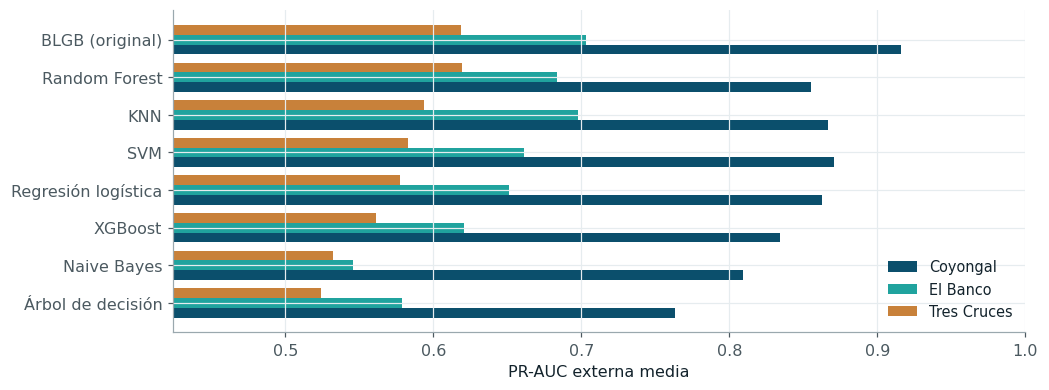

In [11]:
# PR-AUC externa de los ocho modelos en El Banco, Coyongal y Tres Cruces; Friedman y Wilcoxon-Holm
import json as _j
par_all = _j.loads((RESULTADOS.parent / "data" / "processed" / "parametros.json").read_text(encoding="utf-8"))
filas, bloques_extra = [], []
for est in ("el_banco", "coyongal", "tres_cruces"):
    t = tabla_pliegues(f"extra_{est}")
    t["modelo"] = t.modelo.replace({"blgb": "original"})
    piv = t.pivot_table(index="pliegue", columns="modelo", values="pr_auc")
    fr_e = friedman(piv)
    w = wilcoxon_holm(piv, "original")
    mejor_b = piv.drop(columns="original").mean().idxmax()
    filas.append({"Estación objetivo": est.replace("_", " ").title(), "Q_ef (m³/s)": par_all[est]["Q_EF"],
                  "Prevalencia": par_all[est]["prevalencia_train"], "BLGB": piv["original"].mean(),
                  "Mejor modelo de referencia": f"{NOMBRES_MODELO[mejor_b]} ({piv[mejor_b].mean():.4f})",
                  "Rango BLGB": fr_e["rangos"]["original"], "p Friedman": fr_e["p"],
                  "p Wilcoxon-Holm vs mejor": w.set_index("modelo").loc[mejor_b, "p_holm"],
                  "victorias vs mejor": f"{int((piv['original'] > piv[mejor_b]).sum())}/{len(piv)}"})
    piv.columns = [NM.get(c, c) for c in piv.columns]
    piv["estacion"] = est; bloques_extra.append(piv)
extra = pd.DataFrame(filas)
todo = pd.concat(bloques_extra).drop(columns="estacion")
fig, ax = plt.subplots(figsize=(10, 3.8))
medias = pd.concat(bloques_extra).groupby("estacion").mean().T
medias.columns = [c.replace("_", " ").title() for c in medias.columns]
medias = medias.loc[medias.mean(axis=1).sort_values().index]
yy = np.arange(len(medias))
for j, (c, col) in enumerate(zip(medias.columns, (RIO, CAU, SED))):
    ax.barh(yy + (j - 1) * .26, medias[c], height=.26, color=col, label=c)
ax.set_yticks(yy, medias.index); ax.set_xlabel("PR-AUC externa media"); ax.legend(loc="lower right")
ax.set_xlim(max(0, medias.values.min() - .1), 1); plt.show()
fr_global = friedman(todo)
glue("fr_global_p", fr_global["p"], display=False); glue("rango_global", float(fr_global["rangos"][NM["original"]]), display=False)
glue("n_bloques_global", fr_global["n_bloques"], display=False)
glue("extra_gana", int(sum(r["BLGB"] > float(r["Mejor modelo de referencia"].split("(")[-1].rstrip(")")) for r in filas)), display=False)

La tabla siguiente detalla, para cada estación, la descarga efectiva, la prevalencia y la
comparación del modelo propuesto con el mejor modelo de referencia de esa estación.

In [12]:
# Resumen de las tres tareas adicionales
extra.round(4)

,Estación objetivo,Q_ef (m³/s),Prevalencia,BLGB,Mejor modelo de referencia,Rango BLGB,p Friedman,p Wilcoxon-Holm vs mejor,victorias vs mejor
0,El Banco,4765.7178,0.2993,0.7028,KNN (0.6974),2.6667,0.0000,0.6221,6/12
1,Coyongal,6275.0142,0.3699,0.9161,SVM (0.8707),1.6667,0.0000,0.0161,11/12
2,Tres Cruces,3529.1905,0.2677,0.6183,Random Forest (0.6196),3.1667,0.0022,0.5151,6/12


La evaluación en otras tres estaciones del cauce, con su propia descarga efectiva, sus propias
estaciones aguas arriba y el mismo presupuesto de optimización para todos los modelos, matiza el
resultado de Calamar. En Coyongal la ventaja de BLGB es clara y se repite en 11 de los 12 bloques.
En El Banco obtiene la mayor PR-AUC media, pero por un margen pequeño frente a KNN y con victorias
en solo la mitad de los bloques. En Tres Cruces, la estación con menor desempeño de todos los
modelos y la que mostró deriva de medición en {doc}`02_datos`, queda prácticamente empatado con
Random Forest. La prueba de Friedman sobre los 36 bloques de las tres tareas ubica al modelo
propuesto con rango medio {glue:text}`rango_global:.2f` (p = {glue:text}`fr_global_p:.2g`). El
modelo propuesto obtiene la mayor PR-AUC media en {glue:text}`extra_gana` de las tres tareas y
queda empatado en la tercera. La conclusión es que la ventaja del modelo propuesto se reproduce en
otras estaciones, aunque no en todas, y que su magnitud depende de la estación: es grande donde la
señal del caudal futuro es más predecible (Calamar, Coyongal, en el bajo Magdalena, con caudales
amortiguados) y se diluye donde la serie es más ruidosa o tiene problemas de medición.

## Robustez, sensibilidad y límites

La {numref}`fig-robustez` examina la sensibilidad del modelo al peso λ de la supervisión continua
(a) y su comportamiento frente al mejor modelo de referencia bajo tres perturbaciones de los
datos (b).

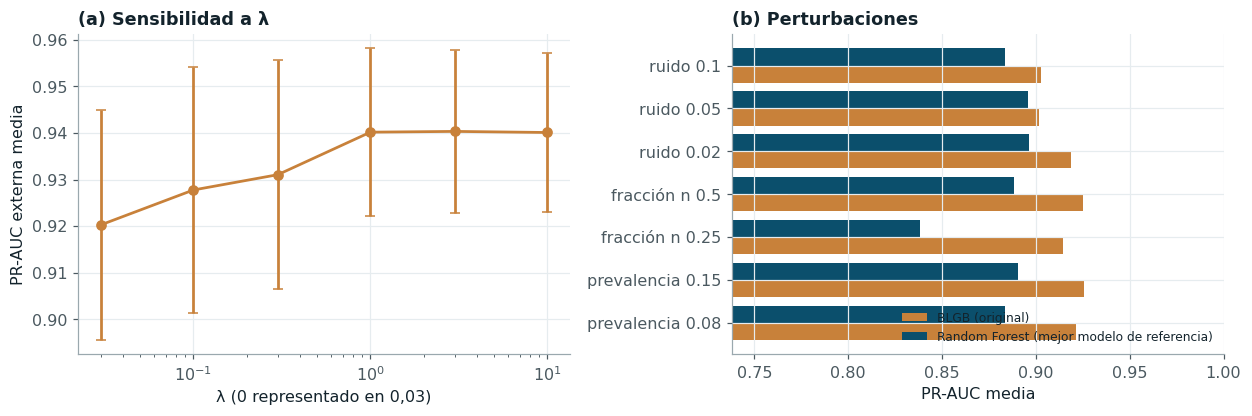

In [13]:
# Sensibilidad a λ y desempeño bajo ruido, desbalance y menor muestra; variación entre semillas
rob = pd.read_csv(RESULTADOS / "robustez" / "robustez.csv")
lam = rob[rob.tipo == "lambda"].groupby("valor").pr_auc.agg(["mean", "std"])
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9))
axs[0].errorbar(lam.index.map(lambda v: max(v, 0.03)), lam["mean"], yerr=lam["std"] / np.sqrt(12), fmt="-o", color=SED, capsize=3)
axs[0].set_xscale("log"); axs[0].set(xlabel="λ (0 representado en 0,03)", ylabel="PR-AUC externa media", title="(a) Sensibilidad a λ")
pert = rob[rob.tipo.isin(["ruido", "desbalance", "muestra"])]
g = pert.groupby(["tipo", "valor", "variante"]).pr_auc.mean().unstack()
etq = [f"{'ruido' if t == 'ruido' else 'prevalencia' if t == 'desbalance' else 'fracción n'} {v:g}" for t, v in g.index]
yy = np.arange(len(g))
axs[1].barh(yy - .2, g["original"], height=.4, color=SED, label=NM["original"])
axs[1].barh(yy + .2, g["benchmark"], height=.4, color=RIO, label=f"{NM[ref]} (mejor modelo de referencia)")
axs[1].set_yticks(yy, etq); axs[1].set_xlim(max(0, g.values.min() - .1), 1); axs[1].legend(loc="lower right", fontsize=8)
axs[1].set(xlabel="PR-AUC media", title="(b) Perturbaciones")
plt.tight_layout(); plt.show()
glue("lam_mejor", float(lam["mean"].idxmax()), display=False)
glue("lam0", float(lam.loc[0.0, "mean"]), display=False); glue("lam_max", float(lam["mean"].max()), display=False)
gan = (g["original"] - g["benchmark"])
glue("pert_min_gan", float(gan.min()), display=False); glue("pert_max_gan", float(gan.max()), display=False)
glue("pert_peor", etq[int(np.argmin(gan.values))], display=False)
sem = rob[rob.tipo == "semilla"].groupby(["variante", "pliegue"]).pr_auc.std().groupby("variante").mean()
glue("sem_orig", float(sem["original"]), display=False); glue("sem_ref", float(sem["benchmark"]), display=False)

La tabla siguiente da las cifras del panel (b).

In [14]:
# PR-AUC media del modelo propuesto y del mejor modelo de referencia en cada perturbación
pd.DataFrame({"propuesto": g["original"], "mejor modelo de referencia": g["benchmark"], "diferencia": gan}).round(4)

propuesto  mejor modelo de referencia  diferencia
tipo       valor                                                   
desbalance 0.08      0.9212                      0.8835      0.0377
           0.15      0.9256                      0.8907      0.0349
muestra    0.25      0.9147                      0.8382      0.0765
           0.50      0.9250                      0.8882      0.0367
ruido      0.02      0.9189                      0.8964      0.0225
           0.05      0.9018                      0.8959      0.0060
           0.10      0.9025                      0.8834      0.0191

La sensibilidad al peso $\lambda$ ({numref}`fig-robustez`a) tiene la forma que predice la teoría.
Con $\lambda = 0$ la PR-AUC media es {glue:text}`lam0:.3f`; crece de forma monótona hasta
$\lambda \approx 1$ y luego se estabiliza en {glue:text}`lam_max:.3f`, de modo que el modelo es
poco sensible al valor exacto una vez que la supervisión continua tiene un peso comparable al de
la tarea. Esa meseta explica que TPE haya elegido valores de $\lambda$ muy distintos según el
pliegue, entre 0,2 y 9,1, sin que el desempeño cambie; el algoritmo genético, que es el optimizador
del modelo final, convergió a valores cercanos a 3,2 en todos los pliegues.

Bajo perturbaciones ({numref}`fig-robustez`b), el modelo propuesto conserva su ventaja sobre el
mejor modelo de referencia en todos los escenarios: la diferencia de PR-AUC va de
{glue:text}`pert_min_gan:+.3f` a {glue:text}`pert_max_gan:+.3f`, y el escenario menos favorable es
«{glue:text}`pert_peor`». La ventaja es mayor cuando se reduce el tamaño de entrenamiento, el
mismo patrón observado en el problema sintético de {doc}`05_modelo_original`: con una cuarta parte
de los días, el modelo de referencia pierde mucho más que el propuesto, porque la supervisión
continua compensa en parte la escasez de casos. El desbalance inducido, al reducir la prevalencia al 8 %, afecta a
ambos modelos en proporción similar, y el ruido multiplicativo del 10 % en los predictores, que
simula errores de medición del caudal, degrada a ambos sin invertir el orden. La variabilidad
entre semillas es pequeña frente a la variabilidad entre bloques: la desviación media entre
cinco semillas es {glue:text}`sem_orig:.4f` para el modelo propuesto y {glue:text}`sem_ref:.4f`
para el modelo de referencia, un orden de magnitud por debajo de la diferencia entre ambos, de modo que la
ventaja no depende de una inicialización afortunada.

## Análisis de errores: dónde no supera a los modelos de referencia

Un promedio favorable puede ocultar regímenes en que el modelo es peor. La tabla siguiente separa
los días de prueba según la posición del caudal actual respecto de la banda y su tendencia de la
última semana, y compara el puntaje de Brier y la PR-AUC de ambos modelos en cada régimen.

In [15]:
# Brier y PR-AUC por régimen hidrológico (posición respecto de la banda y tendencia de 7 días)
pr_o = fo["pred_test"]; pr_r = fin[ref]["pred_test"]
q0 = np.sqrt(D.X_test.calamar_cuad.values); qf = D.y_reg_test.values
LIMS = (8461.29, 11447.63)
tendencia = np.sign(D.X_test.calamar_d7.values)
regimen = np.select([q0 < LIMS[0] * .8, q0 < LIMS[0], q0 <= LIMS[1], q0 <= LIMS[1] * 1.2],
                    ["muy por debajo", "debajo, cerca del límite", "dentro de la banda", "encima, cerca del límite"], "muy por encima")
from sklearn.metrics import brier_score_loss
filas = []
for reg in ["muy por debajo", "debajo, cerca del límite", "dentro de la banda", "encima, cerca del límite", "muy por encima"]:
    for tnd, nom in ((1, "ascenso"), (-1, "descenso")):
        m = (regimen == reg) & (tendencia == tnd)
        if m.sum() < 40 or len(np.unique(y[m])) < 2:
            continue
        filas.append({"régimen actual": reg, "tendencia 7 d": nom, "días": int(m.sum()), "prevalencia": y[m].mean(),
                      "Brier BLGB": brier_score_loss(y[m], pr_o[m]), f"Brier {NM[ref]}": brier_score_loss(y[m], pr_r[m]),
                      "PR-AUC BLGB": average_precision_score(y[m], pr_o[m]), f"PR-AUC {NM[ref]}": average_precision_score(y[m], pr_r[m])})
err = pd.DataFrame(filas)
err["BLGB mejor (Brier)"] = err["Brier BLGB"] < err[f"Brier {NM[ref]}"]
glue("err_pierde", int((~err["BLGB mejor (Brier)"]).sum()), display=False); glue("err_total", len(err), display=False)
err.round(4)

,régimen actual,tendencia 7 d,días,prevalencia,Brier BLGB,Brier Random Forest,PR-AUC BLGB,PR-AUC Random Forest,BLGB mejor (Brier)
0,muy por debajo,ascenso,1218,0.0008,0.0010,0.0009,0.0833,0.0213,False
1,"debajo, cerca del límite",ascenso,731,0.3611,0.1350,0.1511,0.8303,0.7724,True
2,"debajo, cerca del límite",descenso,528,0.0114,0.0161,0.0256,0.1547,0.0654,True
3,dentro de la banda,ascenso,907,0.8809,0.0535,0.0622,0.9948,0.9924,True
4,dentro de la banda,descenso,562,0.6050,0.0993,0.1168,0.9561,0.9168,True
5,"encima, cerca del límite",ascenso,268,0.0037,0.0244,0.0578,0.0833,0.0625,True
6,"encima, cerca del límite",descenso,247,0.2955,0.0519,0.0896,0.9721,0.9522,True


El modelo propuesto tiene un Brier menor que el del mejor modelo de referencia en todos los regímenes con al menos 40 días salvo {glue:text}`err_pierde` de
{glue:text}`err_total`, y su ventaja se concentra en los días que están cerca de los límites de la
banda o dentro de ella, donde la información sobre la distancia al umbral pesa más: con el caudal
por debajo del límite inferior y en ascenso, el Brier baja de 0,151 a 0,135, y dentro de la banda
en descenso, de 0,117 a 0,099. El único régimen en que no lo supera es el de caudales muy por
debajo de la banda en ascenso, donde casi ningún día llega a la banda en quince días (prevalencia
de 0,08 %) y ambos modelos tienen un Brier cercano a cero; la diferencia, del orden de una
diezmilésima, carece de relevancia. Donde el modelo propuesto sí falla, como los modelos de
referencia, es en los ascensos rápidos desde caudales bajos ({doc}`03f_interpretabilidad`): sin
precipitación entre los
predictores, ningún modelo dispone de la causa del ascenso, límite que se discute en las
conclusiones.

## Interpretabilidad del modelo propuesto frente al mejor modelo de referencia

La {numref}`fig-shap-orig` compara la importancia de las variables en ambos modelos, medida con
valores de Shapley por permutaciones en la misma escala de probabilidad.

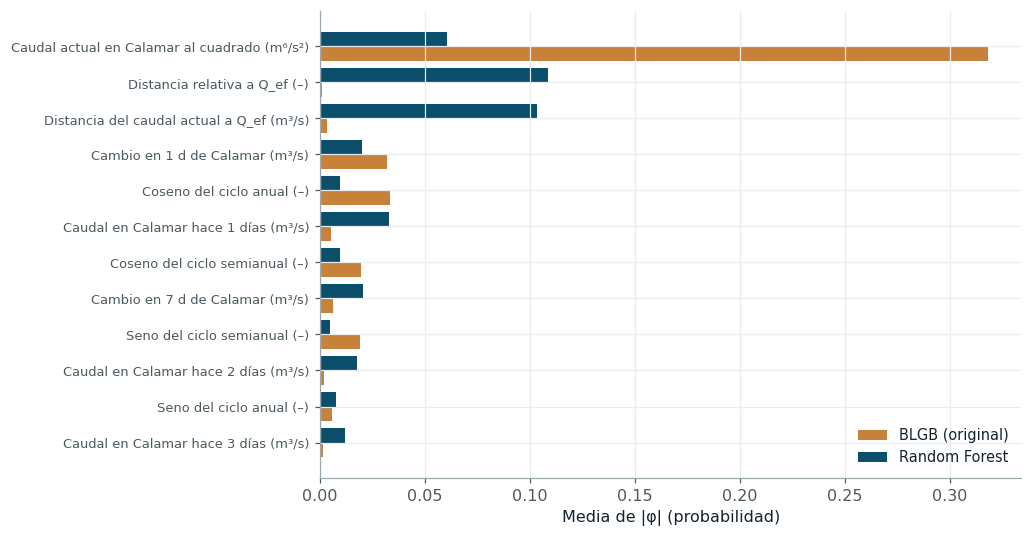

In [16]:
# Importancia media |φ| de cada variable en el modelo propuesto y en el mejor modelo de referencia
sh = pd.read_csv(RESULTADOS.parent / "data" / "dashboard" / "shap_global.csv")
from src.data import etiqueta
a = sh[sh.modelo == "original"].set_index("variable").importancia
b = sh[sh.modelo == ref].set_index("variable").importancia
top = (a + b).sort_values(ascending=False).head(12).index[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5))
yy = np.arange(len(top))
ax.barh(yy - .2, a[top], height=.4, color=SED, label=NM["original"]); ax.barh(yy + .2, b[top], height=.4, color=RIO, label=NM[ref])
ax.set_yticks(yy, [etiqueta(c) for c in top], fontsize=8.5); ax.set_xlabel("Media de |φ| (probabilidad)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
rho = st.spearmanr(a, b.reindex(a.index))[0]
glue("rho_shap", float(rho), display=False)
glue("top_orig", etiqueta(a.idxmax()), display=False); glue("top_ref", etiqueta(b.idxmax()), display=False)
frac_arriba = lambda s: s[[c for c in s.index if not c.startswith(("calamar", "dist", "sen", "cos"))]].sum() / s.sum()
glue("arriba_orig", float(frac_arriba(a)), display=False); glue("arriba_ref", float(frac_arriba(b)), display=False)

Ambos modelos se apoyan en la misma información, el caudal actual y su distancia a la descarga
efectiva, pero la distribuyen de forma distinta: la variable más importante del modelo propuesto
es «{glue:text}`top_orig`» y la del modelo de referencia, «{glue:text}`top_ref`», y la correlación de rangos
entre sus vectores de importancia es de {glue:text}`rho_shap:.2f`. La diferencia es coherente con
el mecanismo de BLGB, que traslada la banda a cada observación a través del caudal de referencia:
la distancia al umbral ya está incorporada en los límites móviles $l$ y $u$, de modo que el modelo
no necesita aprenderla de las variables de distancia y se concentra en la dinámica del cambio.
En ambos modelos la contribución de Puerto Salgar es marginal (menos del 1 % de la importancia),
lo que confirma que la información anticipada útil a quince días está en el estado reciente de
Calamar.